In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROC = Path("../data/processed")
CHARTS = Path("../outputs/charts")
CHARTS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Load the exported tables

In [2]:
# Fact Orders (22 columns)
cols_fact_orders = ['order_id', 'customer_id', 'customer_unique_id', 'order_status', 'purchase_ts', 'approved_ts', 'carrier_ts', 'delivered_ts', 'estimated_ts', 'purchase_date', 'item_count', 'items_revenue', 'freight_total', 'payment_records', 'payment_total', 'review_score', 'is_delivery_valid', 'delivery_days', 'is_late', 'days_vs_estimate', 'is_sale', 'customer_state']
orders = pd.read_csv("fact_orders.csv", header=None, names=cols_fact_orders, parse_dates=["purchase_date"], encoding='latin1')

# Order Items Enriched (11 columns)
cols_items = ['order_id', 'order_item_id', 'price', 'freight_value', 'seller_id', 'category_en', 'is_sale', 'is_late', 'is_delivery_valid', 'review_score', 'customer_state']
items = pd.read_csv("order_items_enriched.csv", header=None, names=cols_items, encoding='latin1')

# Customer Sales (3 columns)
cols_cust = ['customer_unique_id', 'orders', 'revenue']
customers = pd.read_csv("customer_sales.csv", header=None, names=cols_cust, encoding='latin1')

# Seller Sales (3 columns)
cols_seller = ['seller_id', 'orders', 'revenue']
sellers = pd.read_csv("seller_sales.csv", header=None, names=cols_seller, encoding='latin1')

print("Files loaded successfully!")


Files loaded successfully!


In [3]:
orders = pd.read_csv(
    "fact_orders.csv",
    header=None,
    names=cols_fact_orders,
    parse_dates=["purchase_date"],
    encoding="latin1"
)

In [4]:
orders.head(3)

,order_id,customer_id,customer_unique_id,order_status,purchase_ts,approved_ts,carrier_ts,delivered_ts,estimated_ts,purchase_date,...,freight_total,payment_records,payment_total,review_score,is_delivery_valid,delivery_days,is_late,days_vs_estimate,is_sale,customer_state
0,ï»¿00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,2017-09-13,...,13.29,1,72.19,5.0,1,7.61,0.0,9.0,1,RJ
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00,2017-04-26,...,19.93,1,259.83,4.0,1,16.22,0.0,3.0,1,SP
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00,2018-01-14,...,17.87,1,216.87,5.0,1,7.95,0.0,14.0,1,MG


In [5]:
orders.shape   

(99441, 22)

In [6]:
print(orders.columns.tolist())

['order_id', 'customer_id', 'customer_unique_id', 'order_status', 'purchase_ts', 'approved_ts', 'carrier_ts', 'delivered_ts', 'estimated_ts', 'purchase_date', 'item_count', 'items_revenue', 'freight_total', 'payment_records', 'payment_total', 'review_score', 'is_delivery_valid', 'delivery_days', 'is_late', 'days_vs_estimate', 'is_sale', 'customer_state']


In [7]:
items = pd.read_csv(
    "order_items_enriched.csv",
    header=None,
    names=cols_items,
    encoding='latin1'
)

In [8]:
items.head(3)

,order_id,order_item_id,price,freight_value,seller_id,category_en,is_sale,is_late,is_delivery_valid,review_score,customer_state
0,ï»¿00010242fe8c5a6d1ba2dd792cb16214,1,58.9,13.29,48436dade18ac8b2bce089ec2a041202,cool_stuff,1,0.0,1,5.0,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,239.9,19.93,dd7ddc04e1b6c2c614352b383efe2d36,pet_shop,1,0.0,1,4.0,SP
2,000229ec398224ef6ca0657da4fc703e,1,199.0,17.87,5b51032eddd242adc84c38acab88f23d,furniture_decor,1,0.0,1,5.0,MG


In [9]:
items.shape

(112650, 11)

In [10]:
customers = pd.read_csv(
    "customer_sales.csv",
    header=None,
    names=cols_cust,
    encoding='latin1'
)

In [11]:
customers.head(3)

,customer_unique_id,orders,revenue
0,ï»¿17ce6eedc5e8ec89bb143e97521b72b5,1,74.99
1,427e6278802b63b20f34be0d8fb18c51,1,99.00
2,18d54b0a3f713324b17ad5e99fd7d63b,1,99.75


In [12]:
customers.shape

(94983, 3)

In [13]:
sellers = pd.read_csv(
    "seller_sales.csv",
    header=None,
    names=cols_seller,
    encoding='latin1'
)

In [14]:
sellers.head(3)

,seller_id,orders,revenue
0,ï»¿17306570e772e7718c92a562d33f5f1d,29,9669.8
1,f3b80352b986ab4d1057a4b724be19d0,87,10505.1
2,bc47d5d1490df2b36add65d733eafaba,22,964.8


In [15]:
sellers.shape

(3053, 3)

## 2. Cross-check: do the pandas KPIs match SQL and Excel?

In [16]:
sales = orders[orders["is_sale"] == 1]
valid = orders[orders["is_delivery_valid"] == 1]

In [17]:
len(sales)    # expected 98199

98199

In [18]:
round(sales["items_revenue"].sum(), 2)    # expected 13494400.74

np.float64(13494400.74)

In [19]:
sales["customer_unique_id"].nunique()    # expected 94983

94983

In [20]:
round(sales["items_revenue"].sum() / len(sales), 2)    # AOV, expected 137.42

np.float64(137.42)

In [21]:
round(valid["delivery_days"].mean(), 2)    # expected 12.56

np.float64(12.56)

In [22]:
round(valid["is_late"].mean() * 100, 2)    # late %, expected 6.77

np.float64(6.77)

In [23]:
round(valid["review_score"].mean(), 2)    # expected 4.16

np.float64(4.16)

## 3. Missing values in the order table
Missing values here are expected: they come from orders that were never delivered, never reviewed or have no timestamp.

In [24]:
missing = orders.isnull().sum()
missing[missing > 0]
# expected: approved_ts 160, carrier_ts 1783, delivered_ts 2965, review_score 768,
#           delivery_days / is_late / days_vs_estimate 2971 each

approved_ts          160
carrier_ts          1783
delivered_ts        2965
review_score         768
delivery_days       2971
is_late             2971
days_vs_estimate    2971
dtype: int64

## 4. Sales: how has revenue moved over time?

In [25]:
monthly = (
    sales.assign(month=sales["purchase_date"].dt.to_period("M").dt.to_timestamp())
         .groupby("month")
         .agg(orders=("order_id", "count"), revenue=("items_revenue", "sum"))
)
monthly = monthly[monthly.index <= "2018-08-01"]   # Sep 2018 onwards is incomplete
monthly.shape   # expected (23, 2)

(23, 2)

In [26]:
monthly["revenue"].idxmax().strftime("%Y-%m")   # expected 2017-11

'2017-11'

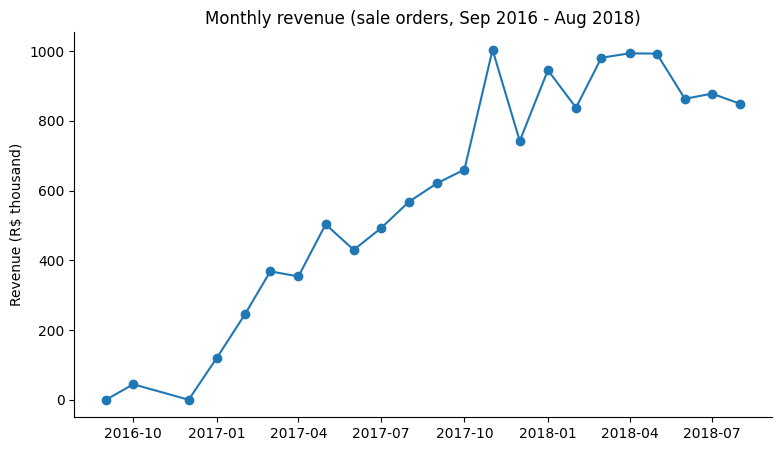

In [27]:
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["revenue"] / 1000, marker="o")
ax.set_title("Monthly revenue (sale orders, Sep 2016 - Aug 2018)")
ax.set_ylabel("Revenue (R$ thousand)")
fig.savefig(CHARTS / "01_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Sales: which categories earn the most?

In [28]:
top_categories = (
    items[items["is_sale"] == 1]
    .groupby("category_en")["price"].sum()
    .sort_values(ascending=False)
    .head(10)
)
top_categories.round(2).head(3)
# expected: health_beauty 1255695.13, watches_gifts 1198185.21, bed_bath_table 1035964.06

category_en
health_beauty     1255695.13
watches_gifts     1198185.21
bed_bath_table    1035964.06
Name: price, dtype: float64

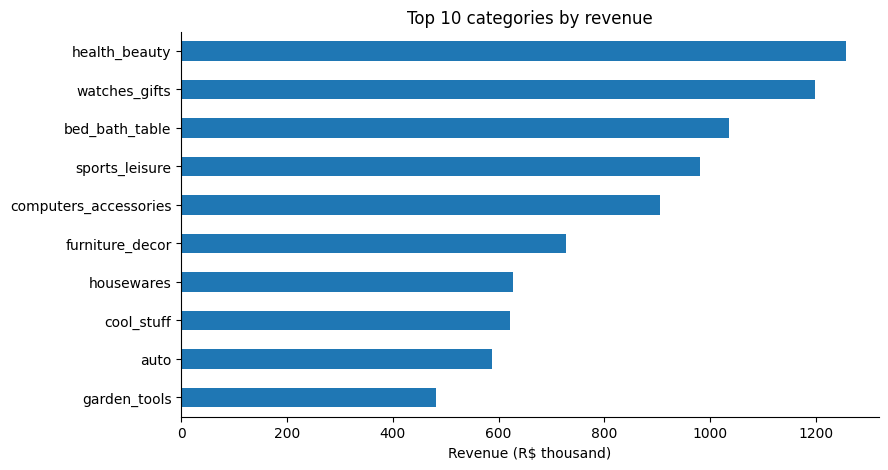

In [29]:
fig, ax = plt.subplots()
(top_categories / 1000).sort_values().plot(kind="barh", ax=ax)
ax.set_title("Top 10 categories by revenue")
ax.set_xlabel("Revenue (R$ thousand)")
ax.set_ylabel("")
fig.savefig(CHARTS / "02_top_categories.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Sales: which states bring the revenue?

In [30]:
state_revenue = (
    items[items["is_sale"] == 1]
    .groupby("customer_state")["price"].sum()
    .sort_values(ascending=False)
)
state_share = (state_revenue / state_revenue.sum() * 100).round(2)
state_share.head(5)
# expected: SP 38.27, RJ 13.43, MG 11.66, RS 5.50, PR 5.02

customer_state
SP    38.27
RJ    13.43
MG    11.66
RS     5.50
PR     5.02
Name: price, dtype: float64

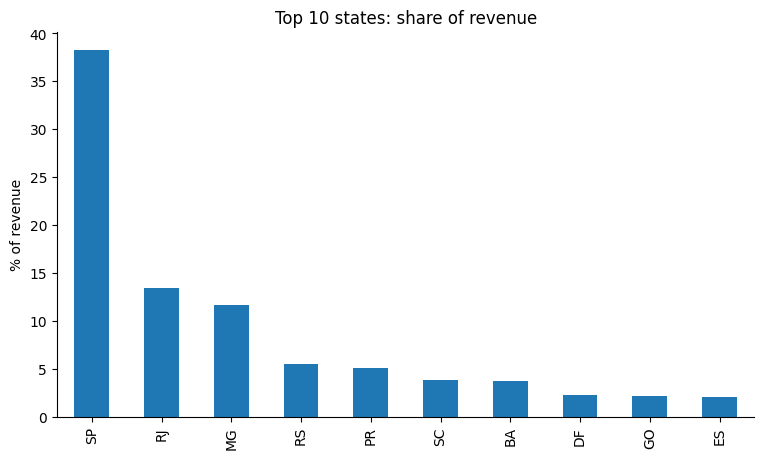

In [31]:
fig, ax = plt.subplots()
state_share.head(10).plot(kind="bar", ax=ax)
ax.set_title("Top 10 states: share of revenue")
ax.set_ylabel("% of revenue")
ax.set_xlabel("")
fig.savefig(CHARTS / "03_state_revenue_share.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Delivery: how long do orders take?

In [32]:
valid["delivery_days"].describe().round(2)    # expected count 96470, mean 12.56, 50% 10.22

count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_days, dtype: float64

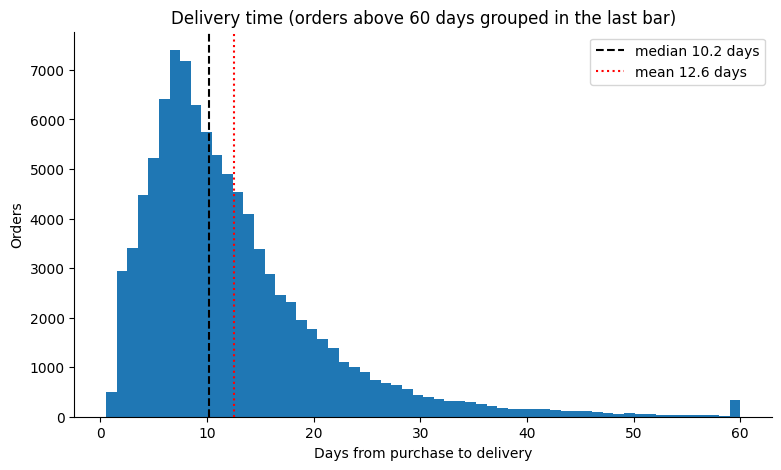

In [33]:
fig, ax = plt.subplots()
ax.hist(valid["delivery_days"].clip(upper=60), bins=60)
ax.axvline(valid["delivery_days"].median(), linestyle="--", color="black",
           label=f"median {valid['delivery_days'].median():.1f} days")
ax.axvline(valid["delivery_days"].mean(), linestyle=":", color="red",
           label=f"mean {valid['delivery_days'].mean():.1f} days")
ax.set_title("Delivery time (orders above 60 days grouped in the last bar)")
ax.set_xlabel("Days from purchase to delivery")
ax.set_ylabel("Orders")
ax.legend()
fig.savefig(CHARTS / "04_delivery_days.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Delivery: which states have the highest late rate? (states with at least 500 delivered orders)

In [34]:
late_by_state = (
    valid.groupby("customer_state")
         .agg(orders=("order_id", "count"), late_pct=("is_late", "mean"))
)
late_by_state["late_pct"] = (late_by_state["late_pct"] * 100).round(2)
late_by_state = late_by_state[late_by_state["orders"] >= 500].sort_values("late_pct", ascending=False)
late_by_state.head(5)
# expected: MA 17.43, CE 13.76, BA 12.16, RJ 12.11, PA 11.21

,orders,late_pct
customer_state,,
MA,717,17.43
CE,1279,13.76
BA,3256,12.16
RJ,12350,12.11
PA,946,11.21


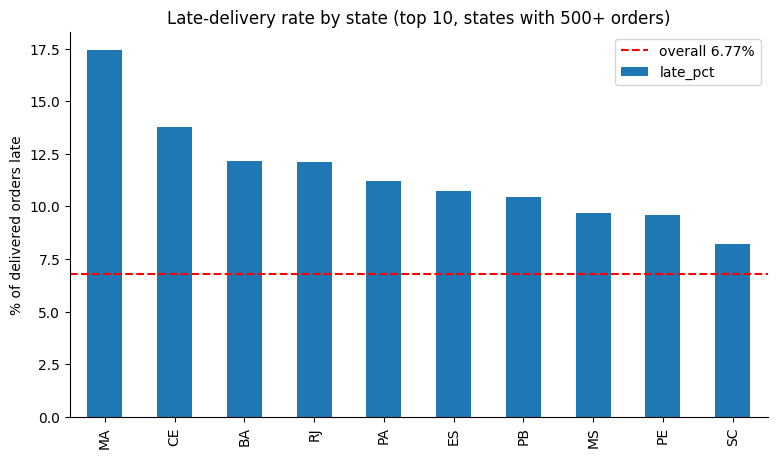

In [35]:
fig, ax = plt.subplots()
late_by_state["late_pct"].head(10).plot(kind="bar", ax=ax)
ax.axhline(valid["is_late"].mean() * 100, linestyle="--", color="red", label="overall 6.77%")
ax.set_title("Late-delivery rate by state (top 10, states with 500+ orders)")
ax.set_ylabel("% of delivered orders late")
ax.set_xlabel("")
ax.legend()
fig.savefig(CHARTS / "05_late_rate_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Satisfaction: how does delay relate to the review score?

In [36]:
def delay_bucket(days_vs_estimate):
    if days_vs_estimate >= 0:
        return "On time / early"
    if days_vs_estimate >= -3:
        return "Late 1-3 days"
    if days_vs_estimate >= -7:
        return "Late 4-7 days"
    return "Late 8+ days"


reviewed = valid.dropna(subset=["review_score"]).copy()
reviewed["bucket"] = reviewed["days_vs_estimate"].apply(delay_bucket)
bucket_order = ["On time / early", "Late 1-3 days", "Late 4-7 days", "Late 8+ days"]

In [37]:
bucket_summary = (
    reviewed.groupby("bucket")
            .agg(orders=("review_score", "count"),
                 avg_score=("review_score", "mean"),
                 low_score_pct=("review_score", lambda s: (s <= 2).mean() * 100))
            .reindex(bucket_order)
            .round(2)
)
bucket_summary
# expected: 89443 | 4.29 | 9.27 ;  1852 | 3.29 | 32.13 ;  1748 | 2.10 | 67.68 ;  2781 | 1.70 | 79.29

,orders,avg_score,low_score_pct
bucket,,,
On time / early,89443,4.29,9.27
Late 1-3 days,1852,3.29,32.13
Late 4-7 days,1748,2.10,67.68
Late 8+ days,2781,1.70,79.29


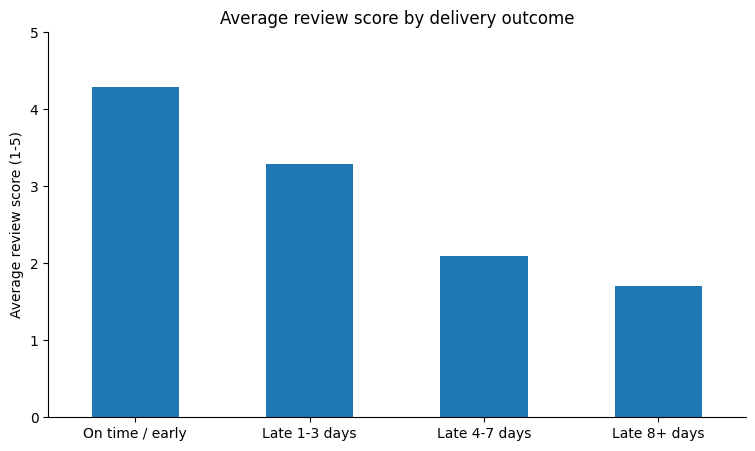

In [38]:
fig, ax = plt.subplots()
bucket_summary["avg_score"].plot(kind="bar", ax=ax)
ax.set_title("Average review score by delivery outcome")
ax.set_ylabel("Average review score (1-5)")
ax.set_xlabel("")
ax.set_ylim(0, 5)
plt.xticks(rotation=0)
fig.savefig(CHARTS / "06_review_vs_delay.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Customers: how many order more than once?

In [39]:
orders_per_customer = customers["orders"].clip(upper=4).value_counts().sort_index()
orders_per_customer
# expected: 1 -> 92096, 2 -> 2651, 3 -> 188, 4 (means 4+) -> 48

orders
1    92096
2     2651
3      188
4       48
Name: count, dtype: int64

In [40]:
round((customers["orders"] > 1).mean() * 100, 2)    # repeat rate, expected 3.04

np.float64(3.04)

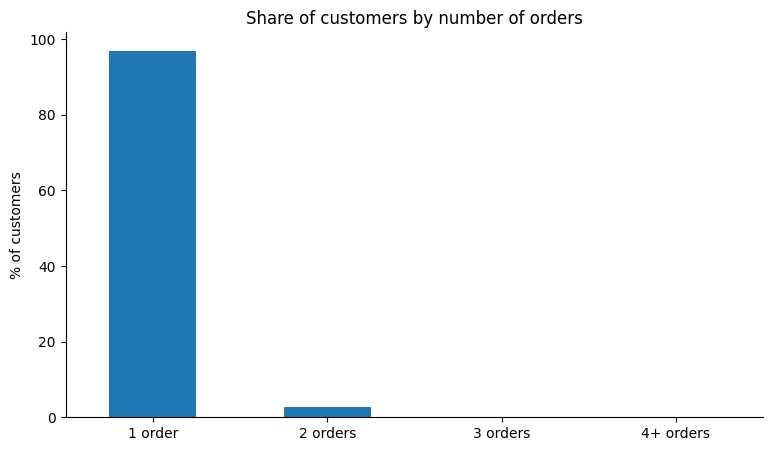

In [41]:
fig, ax = plt.subplots()
share = (orders_per_customer / orders_per_customer.sum() * 100).round(2)
share.index = ["1 order", "2 orders", "3 orders", "4+ orders"]
share.plot(kind="bar", ax=ax)
ax.set_title("Share of customers by number of orders")
ax.set_ylabel("% of customers")
plt.xticks(rotation=0)
fig.savefig(CHARTS / "07_orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Sellers: how concentrated is revenue?

In [42]:
seller_rank = sellers.sort_values("revenue", ascending=False).reset_index(drop=True)
seller_rank["cum_share"] = seller_rank["revenue"].cumsum() / seller_rank["revenue"].sum() * 100
seller_rank["pct_sellers"] = (seller_rank.index + 1) / len(seller_rank) * 100
round(seller_rank.loc[305, "cum_share"], 2)    # top 306 sellers (10%), expected 67.5

np.float64(67.5)

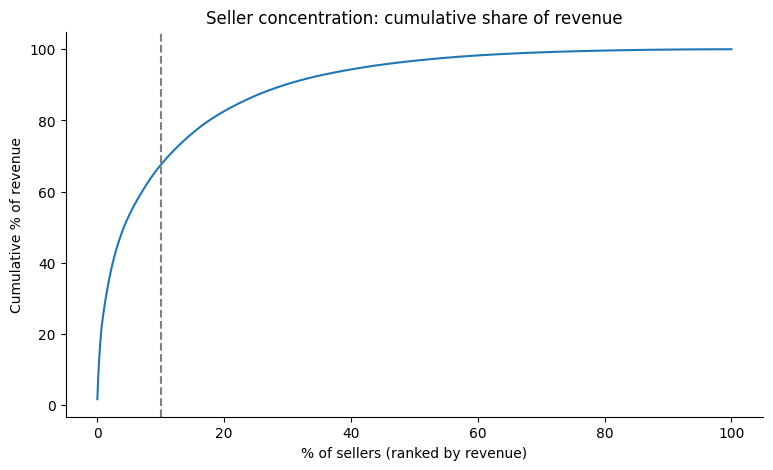

In [43]:
fig, ax = plt.subplots()
ax.plot(seller_rank["pct_sellers"], seller_rank["cum_share"])
ax.axvline(10, linestyle="--", color="grey")
ax.set_title("Seller concentration: cumulative share of revenue")
ax.set_xlabel("% of sellers (ranked by revenue)")
ax.set_ylabel("Cumulative % of revenue")
fig.savefig(CHARTS / "08_seller_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Charts created

In [44]:
sorted(p.name for p in CHARTS.glob("*.png"))    # expected 8 files

['01_monthly_revenue.png',
 '02_top_categories.png',
 '03_state_revenue_share.png',
 '04_delivery_days.png',
 '05_late_rate_by_state.png',
 '06_review_vs_delay.png',
 '07_orders_per_customer.png',
 '08_seller_concentration.png']